In [ ]:
import pandas as pd
import numpy as np
import glob
from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.feature_selection import SelectKBest
from matplotlib import pyplot as plt
import seaborn as sns

Merge 217 per-sample STR genotypes files; Keep variable STRs called in at least 85% samples.

In [ ]:
dfs = []
csv_files = glob.glob("../data/str_csv/*.csv")
for file in csv_files:
    one_file = pd.read_csv(file, index_col=0)
    sample_name = Path(file).stem
    one_file[sample_name] = (
    one_file["genotype"]
    .str.findall(r'\d+')
    .apply(lambda x: np.mean(list(map(int, x))) if isinstance(x, list) else np.nan)
)
    
    dfs.append(one_file[[sample_name]])
final_df = pd.concat(dfs, axis=1)

# STR called in at least 85% samples
final_df = final_df.loc[final_df.isna().sum(axis = 1) < final_df.shape[1]*0.15]
# variable STRs
df_str = final_df.loc[final_df.var(axis=1) > 0]
df_str.to_csv("./data/filtered_df.csv")

Dimensionality reduction

In [ ]:
df_str = pd.read_csv("../data/filtered_df.csv", index_col=0)
k_imp = SimpleImputer(missing_values = np.nan, strategy = "mean")
scaler = StandardScaler()
model = PCA(n_components = 10, 
                random_state=42)

df_imputed = k_imp.fit_transform(df_str.T)
df_scaled = scaler.fit_transform(df_imputed)
pca_data = pd.DataFrame(model.fit_transform(df_scaled))

supp = pd.read_csv("../data/Geo_loc.csv",  encoding="latin1", sep = ",")
pca_data["sample"] = df_str.columns
pca_data = pd.merge(pca_data, supp, left_on="sample", right_on="ID")

Text(0, 0.5, 'PC2')

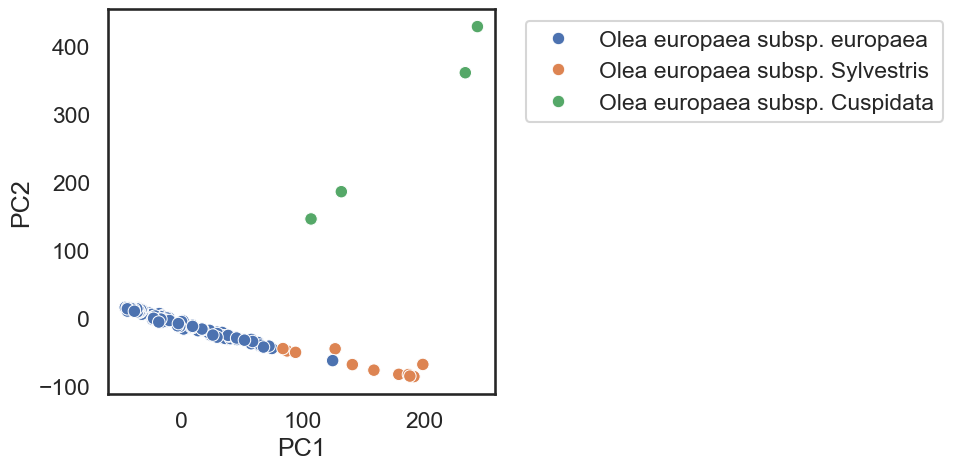

In [10]:
plt.figure(figsize=(5,5), dpi = 100)  
sns.set_theme(style="white", context="talk") 
sns.scatterplot(data = pca_data, x = 0, 
                  y = 1, hue = "Subspecies")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xlabel("PC1")
plt.ylabel("PC2")

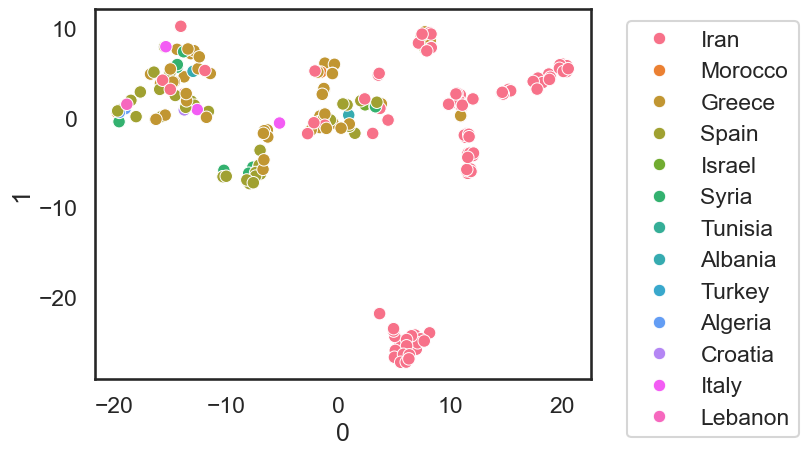

In [28]:
pca_part = pca_data.query("Subspecies in ['Olea europaea subsp. europaea', 'Olea europaea subsp. Sylvestris']")
X_embedded = TSNE(n_components=2, learning_rate='auto',
                  init='random', perplexity=20, random_state=4).fit_transform(pca_part.iloc[:,:10])
tsne_res = pd.DataFrame(X_embedded)
tsne_res["Country"] = pca_part["Country"]
sns.scatterplot(data = tsne_res, x = 0, y = 1, hue = "Country")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")